### Probabilistic Generative Models -- Coursework 1
## Part 2

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

# We set a global configuration for matplotlib to obtain well-readable plots
SMALL_SIZE = 9
MEDIUM_SIZE = 12
BIGGER_SIZE = 12

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)    # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

# fixing random generator for reproducibility
rng = np.random.default_rng(0)

In [188]:
# kernels

def SE(x, y, theta):
    """
    Squared Exponential Kernel (Noiseless)
    """
    # Get hyperparameters
    l = theta[0] # lengthscale
    sigma2 = theta[1] # marginal variance 

    # Compute squared euclidean distance using numpy broadcasting
    x = x.reshape(-1,1) # (N, 1)
    y = y.reshape(1,-1) # (1, M)
    dist_sq = (x - y) ** 2 # (N, M)

    # Apply the SE formula
    K = sigma2 * np.exp(-dist_sq / (2 * l**2))

    return K

def SE_wnoise(x, theta):
    x = np.atleast_1d(x)
    K = SE(x, x, theta)
    _, _, sigma2_e = theta
    return K + sigma2_e * np.eye(len(x))

def Laplace(x, y, theta):
    """
    Laplace Kernel (Noiseless)
    """
    # Get hyperparameters
    l = theta[0] # lengthscale
    sigma2 = theta[1] # marginal variance 

    # Compute absolute distance using numpy broadcasting
    x = x.reshape(-1,1) # (N, 1)
    y = y.reshape(1,-1) # (1, M)
    dist_abs = np.abs(x - y) # (N, M)

    # Apply the Laplace formula 
    K = sigma2 * np.exp(-dist_abs / (2 * l**2))
    return K

def Laplace_wnoise(x, theta):
    x = np.atleast_1d(x)
    K = Laplace(x, x, theta)
    _, _, sigma2_e = theta
    return K + sigma2_e * np.eye(len(x))


In [175]:
class MyFirstGP:

    def __init__(self, kernel, mean=0):
        self.mean = mean # we'll work with mean = 0 here
        self.kernel = kernel # only an id, e.g., 'SE' or 'Lap'

    def init_hypers(self, theta):
    #set the hyperparameters based on the argument theta
        self.theta = theta
	
    def show_hypers(self):
    #shows the current hyperparameters (this might be needed for debugging)
        print(f'hypers are {theta}')

    def load_data(self, x, y):
    #load the input-output observations (dimension N_data)
        self.x_obs = x
        self.y_obs = y

    def set_space(self, x):
    #set the discrete grid on which the GP will be defined (dimension N_space)
        self.space = x
    
    def sample_from_prior(self, trajectories=5):
        if self.kernel == 'SE':
            K = SE(self.space, self.space, self.theta)
        elif self.kernel == 'Laplace':
            K = Laplace(self.space, self.space, self.theta)
        else:
            raise ValueError(f"Unknown kernel: {kernel}")
        
        self.K_prior = K

        n = len(self.space)

        # Cholesky (with jitter)
        L = np.linalg.cholesky(K + 1e-10 * np.eye(n))

        # trajectories from N(0, K):
        z = np.random.randn(n, trajectories)         
        self.prior_samples = (L @ z).T      
    
    def plot_prior(self, title='Plot from the GP prior'):
        x = self.space
        samples = self.prior_samples
        var = np.diag(self.K_prior)

        plt.figure(figsize=(4,2))
        for s in samples:
            plt.plot(x, s, color='gray', alpha=0.5)

        plt.plot(x, np.zeros_like(x), color='black', lw=1, label='prior mean')
        plt.fill_between(
            x,
            -2 * np.sqrt(var),
            2 * np.sqrt(var),
            color='blue',
            alpha=0.2, 
            label = 'credible interval'
        )

        plt.xlabel("x")
        plt.ylabel("f(x)")
        plt.legend()
        plt.title(title)
        plt.show()
        
        
    def nlogp(self, hypers):
        # Get X and y
        X = self.x_obs
        y = self.y_obs
        N = len(y)
        
        # Compute covariance matrix using the helper functions
        if self.kernel == 'SE':
            C = SE_wnoise(X, hypers)
        elif self.kernel == 'Laplace':
            C = Laplace_wnoise(X, hypers)
        
        # Calculate the datafit term 
        C_inv = np.linalg.inv(C)
        datafit = y.T @ C_inv @ y

        # Calculate the penalty term 
        sign, penalty = np.linalg.slogdet(C)

        # Calculate the constant term
        constant = N * np.log(2*np.pi)

        # Calculate log marginal likelihood
        nll = 0.5 * (datafit + penalty + constant)
    
        return nll
    
    def train(self):
        hypers0 = np.asarray(self.theta, dtype=float)

        # (signal var, lengthscale, noise var)
        # heuristic bounds for stable training
        bounds = [
            (1e-12, None),  # sigma2 > 0
            (1e-12, None),  # l > 0
            (1e-12, None),  # sigma2_e >= small positive (keeps K well-conditioned)
        ]

        res = minimize(
            self.nlogp,
            hypers0,
            method='L-BFGS-B',
            bounds=bounds
        )

        self.theta = res.x
        self.final_loss = res.fun

        return res, self.final_loss
    
    def sample_from_posterior(self, trajectories=5):
        # Get data and hyperparameters
        X_train = self.x_obs
        Y_train = self.y_obs
        X_test = self.space
        theta = self.theta
        noise_var = theta[2]

        # Set kernel function
        if self.kernel == 'SE':
            ker = SE
        elif self.kernel == 'Laplace':
            ker = Laplace

        # Compute Covariance Matrices
        K = ker(X_train, X_train, theta) # Similarity between training points (N x N)
        K_s = ker(X_train, X_test, theta) # Similarity between training and test points (N x M)
        K_ss = ker(X_test, X_test, theta) # Similarity between test points (M x M)

        # Add noise to training covariance for inversion
        C = K + noise_var * np.eye(len(X_train))
        
        # Use Cholesky factorisation to compute L such that C = LL^T
        L = np.linalg.cholesky(C + 1e-10 * np.eye(len(X_train)))

        # Solve Lv = y
        v = np.linalg.solve(L, Y_train)
        
        # Solve L^T alpha = v so that alpha = C^-1 y
        alpha = np.linalg.solve(L.T, v)
        
        # Compute posterior mean
        mu_s = K_s.T @ alpha
        
        # Solve LW = K_s so that W = L^-1 K_s
        W = np.linalg.solve(L, K_s)

        # Compute posterior covariance
        cov_s = K_ss - W.T @ W
        
        # Save mean and covariance for plotting later
        self.posterior_mean = mu_s
        self.posterior_cov = cov_s

        # Generate samples from posterior 
        # Use Cholesky factorisation to compute L such that K = LL^T
        n_test = len(X_test)
        L_posterior = np.linalg.cholesky(cov_s + 1e-10 * np.eye(n_test))
        z = np.random.randn(n_test, trajectories)
        
        # Generate samples
        samples = self.posterior_mean.reshape(-1,1) + L_posterior @ z
        self.posterior_samples = samples.T # shape: [trajectories, n_test]
        

    def plot_posterior(self, title='Plot from the GP posterior'):
        x = self.space
        samples = self.posterior_samples
        mu = self.posterior_mean.flatten() # 1D array
        
        # Extract variance from diagonal of covariance matrix
        var = np.diag(self.posterior_cov)
        std = np.sqrt(var)

        plt.figure(figsize=(18, 2))
        plt.plot(self.x_obs, self.y_obs, 'kx', mew=2, label='Observations')
        plt.plot(x, mu, color='black', lw=2, label='Posterior Mean')
        plt.fill_between(
            x, 
            mu - 2 * std, 
            mu + 2 * std, 
            color='blue', 
            alpha=0.2, 
            label='95% Credible Interval'
        )
        
        # Plot Posterior Samples (Trajectories)
        for i, s in enumerate(samples):
            # Only label the first sample to avoid cluttering the legend
            lbl = 'Posterior Samples' if i == 0 else None
            plt.plot(x, s, color='gray', alpha=0.5, lw=1, label=lbl)

        plt.title(title)
        plt.xlim(left=0)
        plt.xlabel("x")
        plt.ylabel("f(x)")
        plt.legend(loc='best')
        plt.show()

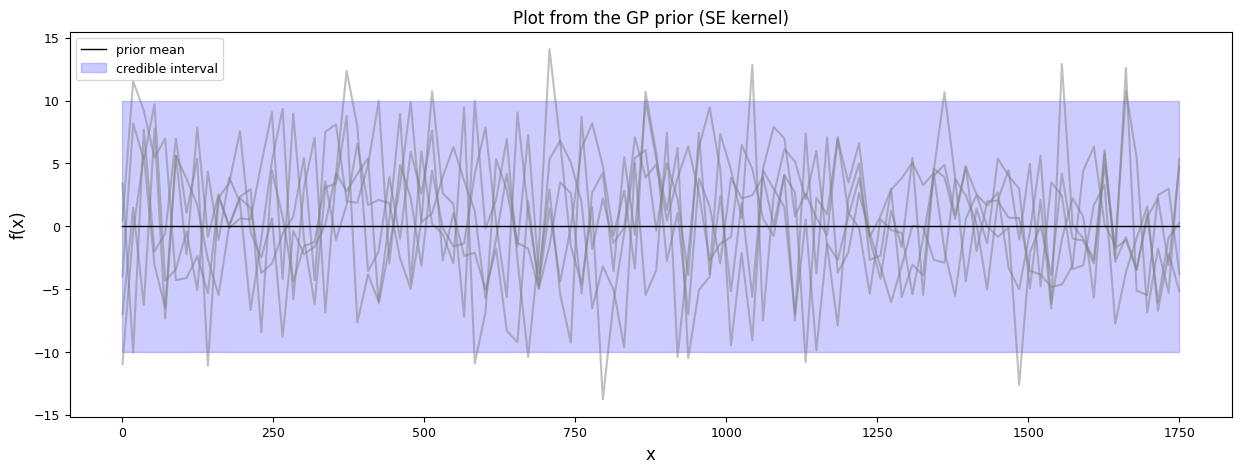

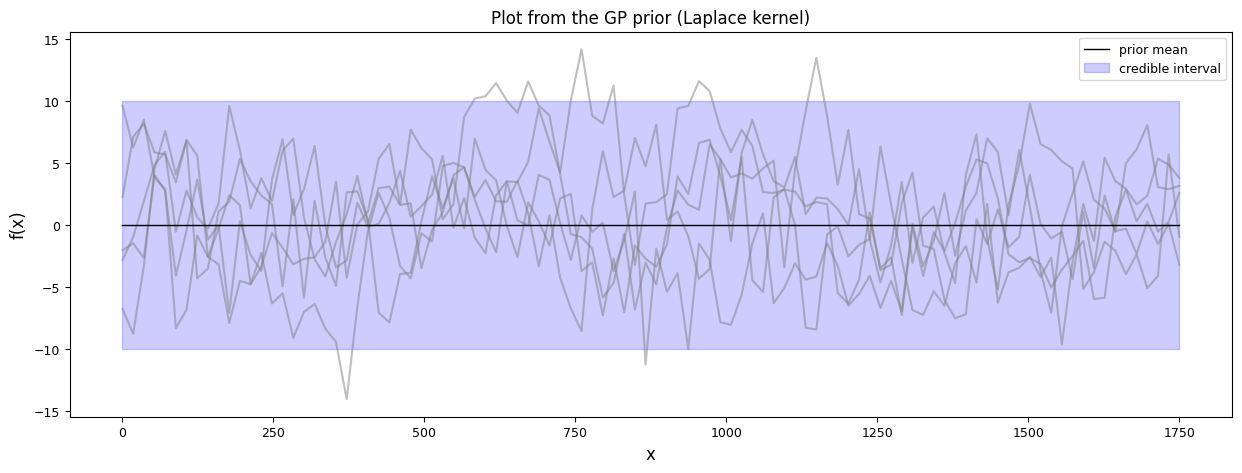

In [138]:
## Sample from the prior

# # SE kernel
gp = MyFirstGP(kernel = 'SE')
gp.init_hypers(theta = [5,25,1])
gp.set_space(np.linspace(0, 1750, 100))

# sample and plot
gp.sample_from_prior(trajectories = 5)
gp.plot_prior(title = 'Plot from the GP prior (SE kernel)')

# Lap kernel
# define model
gp = MyFirstGP(kernel = 'Laplace')
gp.init_hypers( theta = [5,25,1])
gp.set_space(np.linspace(0, 1750, 100))

# sample and plot
gp.sample_from_prior(trajectories = 5)
gp.plot_prior(title = 'Plot from the GP prior (Laplace kernel)')


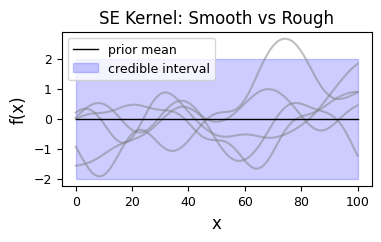

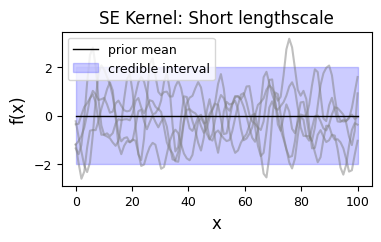

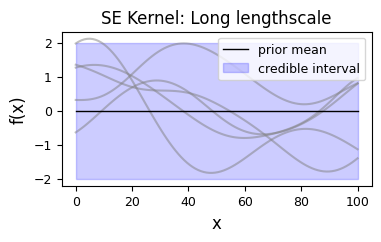

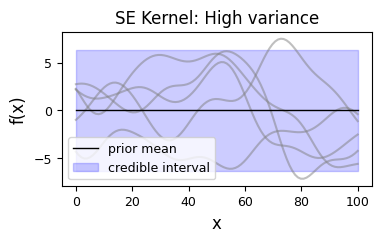

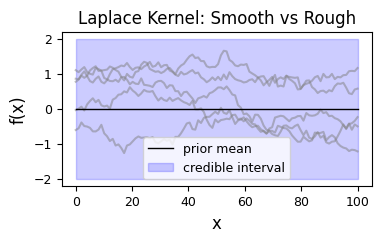

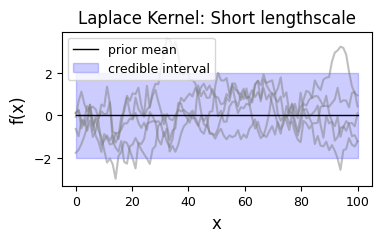

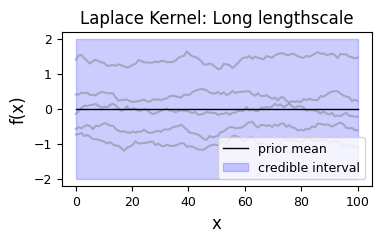

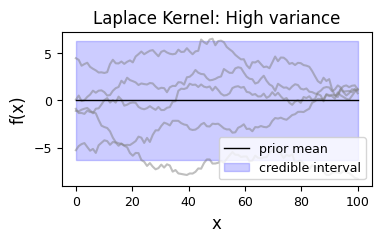

In [166]:
experiments = [
    {"name": "Smooth vs Rough", "theta": [10, 1, 1], "space": np.linspace(0, 100, 100)},
    {"name": "Short lengthscale", "theta": [2, 1, 1],  "space": np.linspace(0, 100, 100)},
    {"name": "Long lengthscale",  "theta": [20, 1, 1], "space": np.linspace(0, 100, 100)},
    {"name": "High variance",     "theta": [10, 10, 1],"space": np.linspace(0, 100, 100)},
]

# Run for SE
for exp in experiments:
    gp_se = MyFirstGP(kernel='SE')
    gp_se.init_hypers(exp['theta'])
    gp_se.set_space(exp['space'])
    gp_se.sample_from_prior(trajectories=5)
    gp_se.plot_prior(title=f"SE Kernel: {exp['name']}")


# Run for Laplace
for exp in experiments:
    gp_lap = MyFirstGP(kernel='Laplace')
    gp_lap.init_hypers(exp['theta'])
    gp_lap.set_space(exp['space'])
    gp_lap.sample_from_prior(trajectories=5)
    gp_lap.plot_prior(title=f"Laplace Kernel: {exp['name']}")

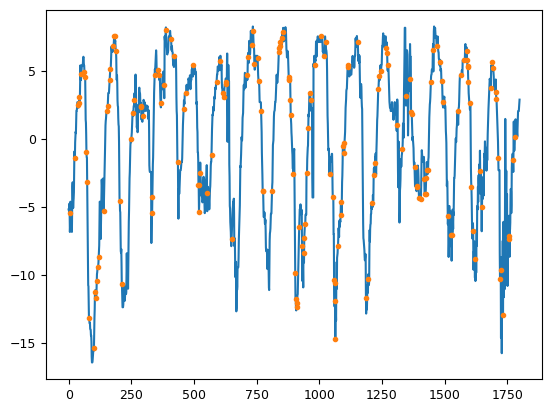

In [184]:
## Data loading
y_data = np.loadtxt('hr2.txt')
y_data -=np.mean(y_data)
x_data = np.arange(len(y_data))

# randomly keep 10% of the observations -- MODIFY THIS TO EXPLORE THE PERFORMANCE FOR VARYING NUMBERS OF OBSERVATIONS
n = len(y_data)
idx = np.random.choice(n, size=n // 10, replace=False)
idx.sort()

x_obs = x_data[idx]
y_obs = y_data[idx]

# You can add legends and labels to this to make it clearer
plt.plot(x_data,y_data, x_obs,y_obs,'.')

In [176]:
## Train the GP

# SE kernel
gpSE = MyFirstGP(kernel = 'SE')
gpSE.init_hypers(theta = [5,25,1])

# optimise
gpSE.load_data(x_obs,y_obs)
_, lossSE = gpSE.train()

print(f'loss of SE kernel is {lossSE}')

# Lap kernel
gpLap = MyFirstGP(kernel = 'Laplace')
gpLap.init_hypers(theta = [5,25,1])

# optimise
gpLap.load_data(x_obs,y_obs)
_, lossLap = gpLap.train()

print(f'loss of Laplace kernel is {lossLap}')


loss of SE kernel is 458.7656064614756
loss of Laplace kernel is 461.6639741118872


In [143]:
experiments = [
    # Experiment Name, Percentage of Data, Initial Theta
    ("10% Data (Baseline)", 10, [5, 25, 1]),
    ("50% Data", 50, [5, 25, 1]),
    ("90% Data", 90, [5, 25, 1]),
    ("small lengthscale", 10, [0.1, 25, 1]),
    ("large lengthscale", 10, [100, 25, 1]),
    ("small variance", 10, [5, 0.1, 1]),
    ("large variance", 10, [5, 100, 1]),
    ("small noise", 10, [5, 25, 0.1]),
    ("large noise", 10, [5, 25, 100]),
]

results = []
print(f"{'Experiment':<20} | {'Kernel':<8} | {'Size':<4} | {'Theta':<13} | {'NLL':<10}")
print("-"*70)
for k_type in ['SE', 'Laplace']:
    for exp, pct, theta in experiments:
        # Prepare data based on percentage
        n = len(y_data)
        size = n // pct
        np.random.seed(42) # For fair comparison 
        idx = np.random.choice(n, size=size, replace=False)
        idx.sort()
        x_obs = x_data[idx]
        y_obs = y_data[idx]
    
        # Run kernel
        gp = MyFirstGP(kernel=k_type)
        gp.load_data(x_obs, y_obs)
        gp.init_hypers(theta=theta)
        
        # Optimse
        res, loss = gp.train()
        theta_str = ", ".join([f"{t:.3g}" for t in theta])
        print(f"{exp:<20} | {k_type:<8} | {pct:<4}% | [{theta_str:<13}] | {loss:<10.3f}")
        results.append({
            'Experiment': exp,
            'Kernel': k_type,
            'Data %': pct,
            'Init Theta': theta,
            'NLL': loss,
        })


Experiment           | Kernel   | Size | Theta         | NLL       
----------------------------------------------------------------------
10% Data (Baseline)  | SE       | 10  % | [5, 25, 1     ] | 458.766   
50% Data             | SE       | 50  % | [5, 25, 1     ] | 107.119   
90% Data             | SE       | 90  % | [5, 25, 1     ] | 60.181    
small lengthscale    | SE       | 10  % | [0.1, 25, 1   ] | 563.515   
large lengthscale    | SE       | 10  % | [100, 25, 1   ] | 458.766   
small variance       | SE       | 10  % | [5, 0.1, 1    ] | 458.766   
large variance       | SE       | 10  % | [5, 100, 1    ] | 458.766   
small noise          | SE       | 10  % | [5, 25, 0.1   ] | 458.766   
large noise          | SE       | 10  % | [5, 25, 100   ] | 458.766   
10% Data (Baseline)  | Laplace  | 10  % | [5, 25, 1     ] | 461.664   
50% Data             | Laplace  | 50  % | [5, 25, 1     ] | 107.055   
90% Data             | Laplace  | 90  % | [5, 25, 1     ] | 60.978    
small len

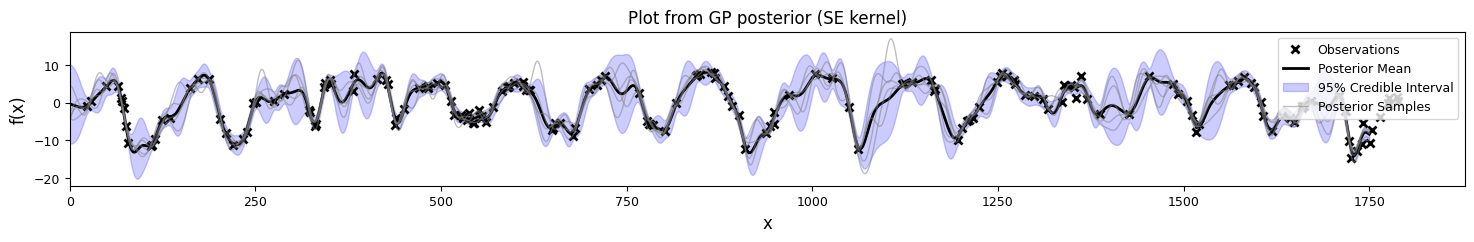

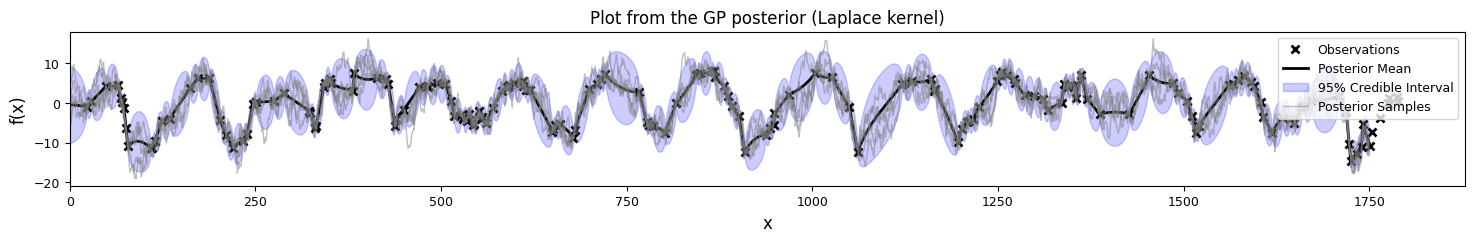

In [177]:
# sample from posterior
gpSE.set_space(np.linspace(0, 1750, 2000))
gpSE.sample_from_posterior(trajectories = 5)
gpSE.plot_posterior(title = 'Plot from GP posterior (SE kernel)')

gpLap.set_space(np.linspace(0, 1750, 2000))
gpLap.sample_from_posterior(trajectories = 5)
gpLap.plot_posterior(title = 'Plot from the GP posterior (Laplace kernel)')

In [186]:
### Quantitative assessment (Task 7)

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

# Predict on the full dataset using SE kernel
gpSE.set_space(x_data) 
gpSE.sample_from_posterior(trajectories=1) 
y_pred_SE = gpSE.posterior_mean

# Predict on the full dataset using Laplace kernel
gpLap.set_space(x_data)
gpLap.sample_from_posterior(trajectories=1)
y_pred_Lap = gpLap.posterior_mean

# Calculate MSE
mse_SE = mse(y_data, y_pred_SE)
mse_Lap = mse(y_data, y_pred_Lap)

# Print results
print(f"{'Metric':<10} | {'SE Kernel':<15} | {'Laplace Kernel':<15}")
print("-" * 45)
print(f"{'NLL':<10} | {lossSE:<15.4f} | {lossLap:<15.4f}")
print(f"{'MSE':<10} | {mse_SE:<15.4f} | {mse_Lap:<15.4f}")

Metric     | SE Kernel       | Laplace Kernel 
---------------------------------------------
NLL        | 458.7656        | 461.6640       
MSE        | 3.8420          | 3.3749         
